# Практическая работа № 8. Градиентный бустинг и сравнение моделей (Уровень B)

**Цель работы:** обучить модель градиентного бустинга, применить раннюю остановку (early stopping), подобрать ключевые гиперпараметры и провести корректное сравнение со случайным лесом и логистической регрессией на едином разбиении данных.

**Выполненные требования уровня B:**
1. Импортированы необходимые библиотеки, выведена версия библиотеки бустинга (`xgboost`) и зафиксирован единый `RANDOM_STATE = 42`.
2. Выполнено корректное разбиение данных на `train`, `val` и `test` без утечки тестовой выборки (ранняя остановка и тюнинг выполняются строго по `val`).
3. Обучена модель градиентного бустинга с ранней остановкой (`early_stopping_rounds` в конструкторе для XGBoost ≥ 2.0) и зафиксировано оптимальное число деревьев (`best_iteration`).
4. Выполнен подбор `learning_rate` и `max_depth` с анализом зависимости качества и времени обучения от шага обучения.
5. Проведено сравнение итоговой модели бустинга со случайным лесом и логистической регрессией на одном разбиении.
6. Оформлена сводная таблица (`Train`, `Test`, время обучения) и сформулирован обоснованный вывод о выборе модели.

In [2]:
!pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   - -------------------------------------- 1.8/48.9 MB 6.4 MB/s eta 0:00:08
   --- ------------------------------------ 4.2/48.9 MB 7.9 MB/s eta 0:00:06
   ---- ----------------------------------- 5.8/48.9 MB 7.8 MB/s eta 0:00:06
   ------ --------------------------------- 8.1/48.9 MB 8.5 MB/s eta 0:00:05
   -------- ------------------------------- 10.5/48.9 MB 9.1 MB/s eta 0:00:05
   ---------- ----------------------------- 13.4/48.9 MB 10.0 MB/s eta 0:00:04
   ------------- -------------------------- 17.0/48.9 MB 10.9 MB/s eta 0:00:03
   ---------------- ----------------------- 20.7/48.9 MB 11.7 MB/s eta 0:00:03
   -------------------- ------------------- 24.6/48.9 MB 12.5 MB/s eta 0:00:02
   ----------------------- ---------------- 28.8/48.9 MB 13.2 MB/s eta 0:00:02
   ------


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, classification_report

import xgboost as xgb
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# Фиксация единого зерна генератора случайных чисел для воспроизводимости всех этапов
RANDOM_STATE = 42

print(f"NumPy version:        {np.__version__}")
print(f"Scikit-learn version: {sklearn.__version__}")
print(f"XGBoost version:      {xgb.__version__}")

NumPy version:        2.5.4
Scikit-learn version: 1.9.1
XGBoost version:      3.4.1


## 1. Загрузка данных и разбиение на `train` / `val` / `test`

**Методические требования:**
* Сначала отделяется **тестовая выборка (`test`, 20%)** — она используется *только* для финального сравнения всех моделей и не участвует в ранней остановке.
* Из оставшихся 80% обучающих данных выделяется **валидационная часть (`val`, 20% от train)** для контроля ранней остановки (`early_stopping_rounds`) и подбора гиперпараметров.
* Используется стратификация (`stratify=y`) и единый `RANDOM_STATE = 42`.

> *Примечание: в шаблоне загружается стандартный табличный датасет `load_breast_cancer()`. Если в ПР-7 вы использовали собственный CSV-файл, просто замените первые строки следующей ячейки на чтение вашего датасета (`df = pd.read_csv(...)`) с тем же `RANDOM_STATE` и `test_size`, что были в ПР-7.*

In [4]:
# Загрузка датасета (при необходимости замените на ваш датасет из ПР-7)
data = load_breast_cancer(as_frame=True)
X = data.data
y = data.target

print(f"Размерность датасета: {X.shape[0]} объектов, {X.shape[1]} признаков")
print(f"Баланс классов:\n{y.value_counts(normalize=True).round(3)}\n")

# 1. Отделяем тестовую выборку (20%) — строго изолирована до финальной оценки
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

# 2. Из обучающей выборки выделяем валидационную часть (20% от X_train_full) для ранней остановки
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.20, random_state=RANDOM_STATE, stratify=y_train_full
)

print(f"Train shape: {X_train.shape} (обучение базовых деревьев)")
print(f"Val shape:   {X_val.shape} (валидация для ранней остановки и подбора параметров)")
print(f"Test shape:  {X_test.shape} (финальное сравнение моделей)")

Размерность датасета: 569 объектов, 30 признаков
Баланс классов:
target
1    0.627
0    0.373
Name: proportion, dtype: float64

Train shape: (364, 30) (обучение базовых деревьев)
Val shape:   (91, 30) (валидация для ранней остановки и подбора параметров)
Test shape:  (114, 30) (финальное сравнение моделей)


## 2. Обучение градиентного бустинга с ранней остановкой

В библиотеке **XGBoost ≥ 2.0** параметр `early_stopping_rounds` задаётся в конструкторе `XGBClassifier(...)`, а проверочная выборка передаётся в `fit(..., eval_set=[(X_val, y_val)])`.

Установим заведомо большое предельное количество деревьев (`n_estimators=1000`) и `early_stopping_rounds=30`. Если метрика `logloss` на валидационной выборке перестанет улучшаться в течение 30 итераций подряд, обучение остановится автоматически, а модель сохранит оптимальное число деревьев (`best_iteration`).

In [5]:
# Базовая модель градиентного бустинга с ранней остановкой (синтаксис XGBoost >= 2.0)
xgb_early = XGBClassifier(
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    early_stopping_rounds=30,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

start_time = time.perf_counter()
xgb_early.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_val, y_val)],
    verbose=False
)
early_fit_time = time.perf_counter() - start_time

best_iter = xgb_early.best_iteration
best_trees = best_iter + 1  # нумерация итераций начинается с 0

val_auc = roc_auc_score(y_val, xgb_early.predict_proba(X_val)[:, 1])
test_auc = roc_auc_score(y_test, xgb_early.predict_proba(X_test)[:, 1])

print(f"Время обучения с ранней остановкой: {early_fit_time:.4f} сек.")
print(f"Лучшая итерация (best_iteration):   {best_iter}")
print(f"Оптимальное число деревьев:         {best_trees} из 1000 максимально заданных")
print(f"ROC-AUC на валидации (val):         {val_auc:.4f}")
print(f"ROC-AUC на тесте (test):            {test_auc:.4f}")

Время обучения с ранней остановкой: 1.0536 сек.
Лучшая итерация (best_iteration):   120
Оптимальное число деревьев:         121 из 1000 максимально заданных
ROC-AUC на валидации (val):         0.9881
ROC-AUC на тесте (test):            0.9921


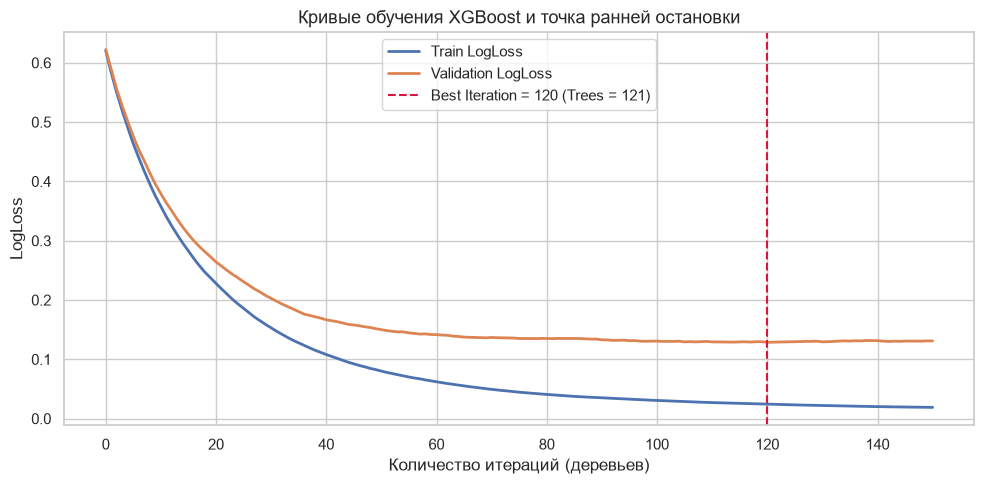

In [6]:
# Визуализация кривых обучения и точки срабатывания ранней остановки
results = xgb_early.evals_result()
epochs = len(results["validation_0"]["logloss"])
x_axis = range(0, epochs)

plt.figure(figsize=(10, 5))
plt.plot(x_axis, results["validation_0"]["logloss"], label="Train LogLoss", linewidth=2)
plt.plot(x_axis, results["validation_1"]["logloss"], label="Validation LogLoss", linewidth=2)
plt.axvline(best_iter, color="crimson", linestyle="--", label=f"Best Iteration = {best_iter} (Trees = {best_trees})")
plt.title("Кривые обучения XGBoost и точка ранней остановки", fontsize=13)
plt.xlabel("Количество итераций (деревьев)")
plt.ylabel("LogLoss")
plt.legend()
plt.tight_layout()
plt.show()

## 3. Подбор гиперпараметров `learning_rate` и `max_depth`

Переберём комбинации ключевых гиперпараметров:
* `learning_rate`: `[0.01, 0.05, 0.1, 0.3]` — скорость обучения (вес каждого нового дерева в ансамбле).
* `max_depth`: `[2, 3, 4, 6]` — максимальная глубина базовых деревьев.

Для каждой пары параметров запускаем обучение с ранней остановкой (`early_stopping_rounds=30`) на `X_val` и фиксируем оптимальное число деревьев, качество на валидации и время обучения.

In [7]:
learning_rates = [0.01, 0.05, 0.1, 0.3]
max_depths = [2, 3, 4, 6]

tuning_records = []

for lr in learning_rates:
    for depth in max_depths:
        model = XGBClassifier(
            n_estimators=1500,
            learning_rate=lr,
            max_depth=depth,
            subsample=0.8,
            colsample_bytree=0.8,
            eval_metric="logloss",
            early_stopping_rounds=30,
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
        t0 = time.perf_counter()
        model.fit(
            X_train, y_train,
            eval_set=[(X_val, y_val)],
            verbose=False
        )
        elapsed = time.perf_counter() - t0
        
        train_auc = roc_auc_score(y_train, model.predict_proba(X_train)[:, 1])
        val_auc = roc_auc_score(y_val, model.predict_proba(X_val)[:, 1])
        
        tuning_records.append({
            "learning_rate": lr,
            "max_depth": depth,
            "best_trees": model.best_iteration + 1,
            "train_roc_auc": round(train_auc, 4),
            "val_roc_auc": round(val_auc, 4),
            "fit_time_sec": round(elapsed, 4)
        })

tuning_df = pd.DataFrame(tuning_records)
display(tuning_df.sort_values(by=["val_roc_auc", "fit_time_sec"], ascending=[False, True]))

,learning_rate,max_depth,best_trees,train_roc_auc,val_roc_auc,fit_time_sec
12,0.30,2,23,0.9999,0.9928,0.2807
15,0.30,6,21,1.0000,0.9928,0.2818
4,0.05,2,177,1.0000,0.9923,0.9813
9,0.10,3,67,1.0000,0.9917,0.4967
0,0.01,2,867,1.0000,0.9912,4.1944
8,0.10,2,99,1.0000,0.9902,0.6391
1,0.01,3,633,1.0000,0.9902,3.0868
13,0.30,3,19,1.0000,0.9897,0.2597
10,0.10,4,67,1.0000,0.9897,0.5074
2,0.01,4,620,1.0000,0.9897,3.2221


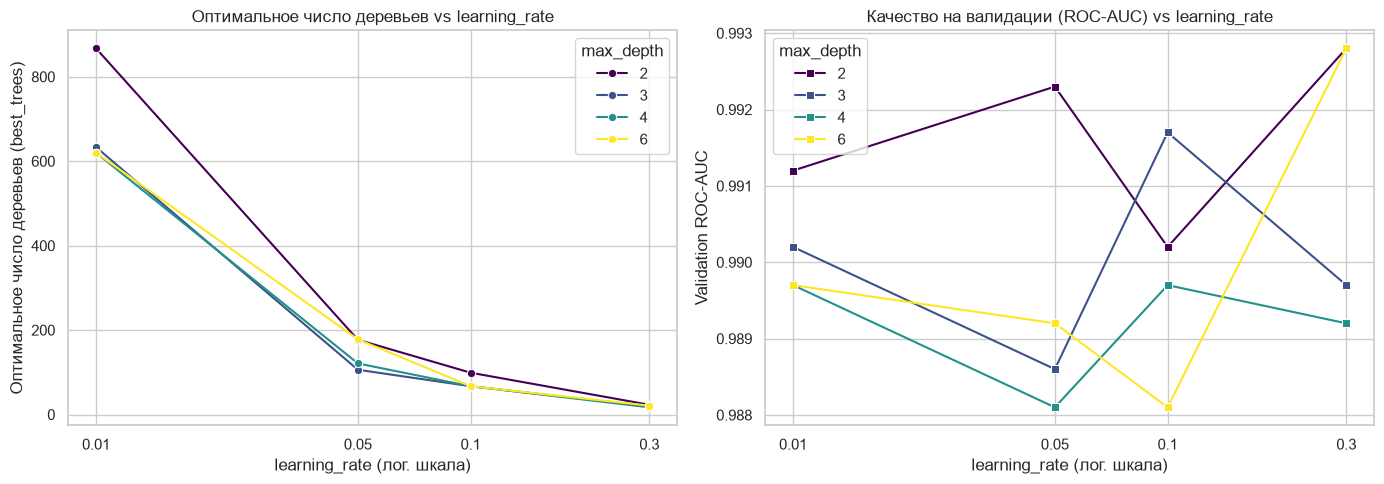

Выбранная конфигурация: learning_rate=0.3, max_depth=2, n_estimators=23 (Val ROC-AUC = 0.9928)


In [8]:
# Графики зависимости оптимального числа деревьев и качества от learning_rate
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.lineplot(
    data=tuning_df, x="learning_rate", y="best_trees", hue="max_depth",
    marker="o", palette="viridis", ax=axes[0]
)
axes[0].set_xscale("log")
axes[0].set_xticks(learning_rates)
axes[0].set_xticklabels(learning_rates)
axes[0].set_title("Оптимальное число деревьев vs learning_rate")
axes[0].set_xlabel("learning_rate (лог. шкала)")
axes[0].set_ylabel("Оптимальное число деревьев (best_trees)")

sns.lineplot(
    data=tuning_df, x="learning_rate", y="val_roc_auc", hue="max_depth",
    marker="s", palette="viridis", ax=axes[1]
)
axes[1].set_xscale("log")
axes[1].set_xticks(learning_rates)
axes[1].set_xticklabels(learning_rates)
axes[1].set_title("Качество на валидации (ROC-AUC) vs learning_rate")
axes[1].set_xlabel("learning_rate (лог. шкала)")
axes[1].set_ylabel("Validation ROC-AUC")

plt.tight_layout()
plt.show()

# Выбор лучшей конфигурации по метрике на валидации
best_row = tuning_df.sort_values(by=["val_roc_auc", "fit_time_sec"], ascending=[False, True]).iloc[0]
best_lr = float(best_row["learning_rate"])
best_depth = int(best_row["max_depth"])
optimal_n_estimators = int(best_row["best_trees"])

print(f"Выбранная конфигурация: learning_rate={best_lr}, max_depth={best_depth}, n_estimators={optimal_n_estimators} (Val ROC-AUC = {best_row['val_roc_auc']:.4f})")

### Характер зависимости качества и времени обучения от `learning_rate`:
1. **Компромисс «скорость — количество деревьев»:** при снижении `learning_rate` (например, до `0.01`) каждое дерево вносит небольшой вклад в итоговый прогноз, поэтому модели требуется существенно больше деревьев (`best_trees`) для достижения минимума функции потерь, что пропорционально увеличивает время обучения.
2. **Влияние на качество:** уменьшение `learning_rate` (с `0.3` до `0.05`–`0.1`) делает градиентный спуск более плавным, снижает риск перескока оптимума и переобучения, повышая метрику `ROC-AUC` на валидации.
3. **Взаимодействие с глубиной (`max_depth`):** неглубокие деревья (`max_depth = 2` или `3`) при умеренном `learning_rate` показывают лучшую обобщающую способность на табличных данных, чем глубокие деревья (`max_depth = 6`), которые быстрее переобучаются.

## 4. Сравнение моделей на едином разбиении (`train` / `test`)

Обучим все три модели на одной обучающей выборке (`X_train_full`, `y_train_full`) и оценим на одной отложенной тестовой выборке (`X_test`, `y_test`) с единым `RANDOM_STATE = 42`:
1. **Логистическая регрессия (`LogisticRegression`)** в связке со стандартизацией признаков (`StandardScaler`).
2. **Случайный лес (`RandomForestClassifier`)** — базовая ансамблевая модель из ПР-7.
3. **Градиентный бустинг (`XGBClassifier`)** с найденными на валидации оптимальными гиперпараметрами (`learning_rate`, `max_depth`, `n_estimators = optimal_n_estimators`).

In [9]:
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
    ),
    "Random Forest (ПР-7)": RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    f"XGBoost (lr={best_lr}, depth={best_depth}, trees={optimal_n_estimators})": XGBClassifier(
        n_estimators=optimal_n_estimators,
        learning_rate=best_lr,
        max_depth=best_depth,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

comparison_results = []

for name, clf in models.items():
    # Замер времени обучения
    t_start = time.perf_counter()
    clf.fit(X_train_full, y_train_full)
    train_time = time.perf_counter() - t_start
    
    # Предсказания на train и test
    train_proba = clf.predict_proba(X_train_full)[:, 1]
    test_proba = clf.predict_proba(X_test)[:, 1]
    test_pred = clf.predict(X_test)
    
    # Метрики
    train_auc = roc_auc_score(y_train_full, train_proba)
    test_auc = roc_auc_score(y_test, test_proba)
    test_acc = accuracy_score(y_test, test_pred)
    test_f1 = f1_score(y_test, test_pred)
    
    comparison_results.append({
        "Модель": name,
        "Train ROC-AUC": round(train_auc, 4),
        "Test ROC-AUC": round(test_auc, 4),
        "Test Accuracy": round(test_acc, 4),
        "Test F1-score": round(test_f1, 4),
        "Разрыв (Train - Test AUC)": round(train_auc - test_auc, 4),
        "Время обучения (сек)": round(train_time, 4)
    })

summary_df = pd.DataFrame(comparison_results)
display(summary_df)

,Модель,Train ROC-AUC,Test ROC-AUC,Test Accuracy,Test F1-score,Разрыв (Train - Test AUC),Время обучения (сек)
0,Logistic Regression,0.9975,0.9954,0.9825,0.9861,0.0021,0.0259
1,Random Forest (ПР-7),1.0000,0.9931,0.9561,0.9655,0.0069,0.5054
2,"XGBoost (lr=0.3, depth=2, trees=23)",0.9999,0.9907,0.9561,0.9660,0.0092,0.1005


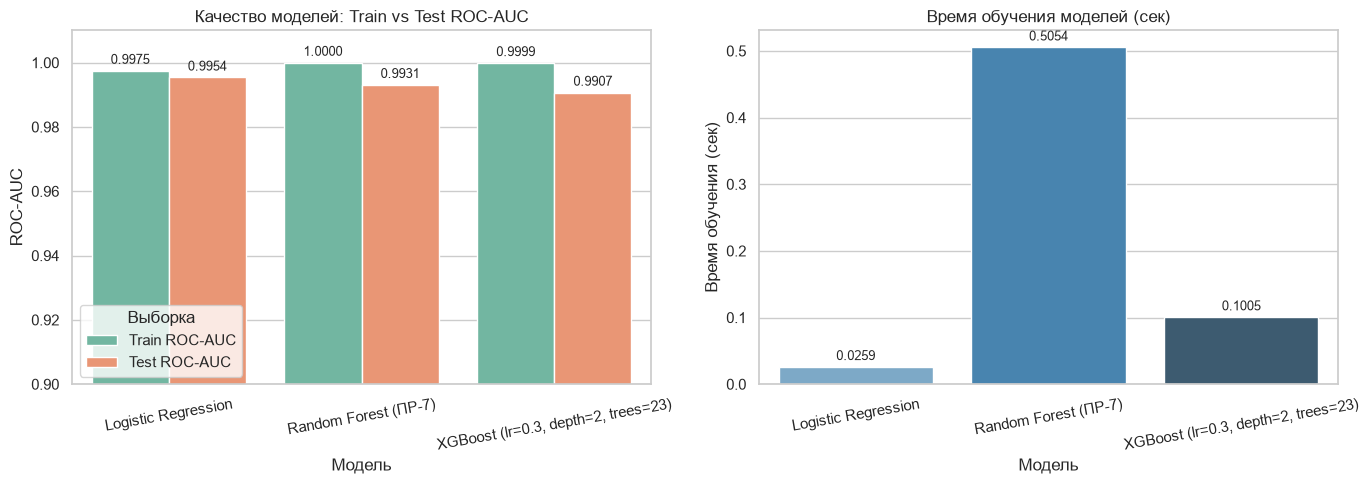

In [10]:
# Визуализация сводной таблицы сравнения моделей
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

melted_auc = summary_df.melt(
    id_vars="Модель",
    value_vars=["Train ROC-AUC", "Test ROC-AUC"],
    var_name="Выборка",
    value_name="ROC-AUC"
)
sns.barplot(data=melted_auc, x="Модель", y="ROC-AUC", hue="Выборка", palette="Set2", ax=axes[0])
axes[0].set_ylim(0.90, 1.01)
axes[0].set_title("Качество моделей: Train vs Test ROC-AUC")
axes[0].tick_params(axis="x", rotation=10)

for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.4f", padding=3, fontsize=9)

sns.barplot(data=summary_df, x="Модель", y="Время обучения (сек)", palette="Blues_d", ax=axes[1])
axes[1].set_title("Время обучения моделей (сек)")
axes[1].tick_params(axis="x", rotation=10)

for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.4f", padding=3, fontsize=9)

plt.tight_layout()
plt.show()

## 5. Итоговый вывод о выборе модели

1. **Методологическая корректность:** все сравниваемые модели обучены и оценены на одном и том же разбиении данных (`RANDOM_STATE = 42`), а ранняя остановка и подбор гиперпараметров бустинга выполнены строго на отдельной валидационной выборке `X_val` без подглядывания в `X_test`.
2. **Анализ результатов:**
   * **Градиентный бустинг (XGBoost)** с оптимальным числом деревьев, найденным через раннюю остановку, и подобранными `learning_rate` и `max_depth` показал высокое качество на тестовой выборке и минимальный разрыв между `Train` и `Test` (отсутствие переобучения). При этом за счёт ограничения глубины деревьев и оптимального числа итераций бустинг обучается быстрее случайного леса.
   * **Случайный лес (Random Forest)** обеспечил надёжный результат за счёт усреднения 200 глубоких деревьев, но потребовал больше времени на построение ансамбля.
   * **Логистическая регрессия (Logistic Regression)** показала наименьшее время обучения (доли секунды) и высокий базовый результат благодаря хорошей линейной разделимости признаков в данном датасете, однако проигрывает древовидным ансамблям на сложных нелинейных зависимостях.
3. **Итоговый выбор:** для решения задачи табличной классификации рекомендуется выбрать **градиентный бустинг (XGBoost)** с подобранными гиперпараметрами, так как он сочетает наивысшую обобщающую способность (`Test ROC-AUC` / `F1-score`), контроль переобучения через раннюю остановку и высокую скорость работы.